# Lab 03 — Image Enhancement and Intensity Transformations
**The University of Azad Jammu and Kashmir — Department of Software Engineering**
Digital Image Processing Lab · Lab Instructor: Engr. Fahad Nisar · Semester: Fifth · Session: 2024-28 (SE)

**Name:** Zulqarnain Mohi Ud Din  **Roll No:** 2024-SE-07

## 0. Setup, image loading and numeric safety

In [1]:
import json, os
from fractions import Fraction
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
os.makedirs("figures", exist_ok=True)
RESULTS = {"dry": {}, "img": {}}          # collected for the Word report

def save(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def show(images, titles, name, figw=3.2):
    """Display images with the full 0-255 grayscale range and save the figure."""
    fig, axes = plt.subplots(1, len(images), figsize=(figw * len(images), figw + 0.4))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=9)
        ax.axis("off")
    plt.tight_layout(); save(name); plt.show()

def dry(key, title, headers, rows):
    """Print a dry-run table and record it for the report."""
    rows = [[str(c) for c in r] for r in rows]
    RESULTS["dry"][key] = {"title": title, "headers": headers, "rows": rows}
    print(title)
    cols = [headers] + rows
    w = [max(len(r[i]) for r in cols) for i in range(len(headers))]
    for k, r in enumerate(cols):
        print("  " + " | ".join(c.rjust(x) for c, x in zip(r, w)))
        if k == 0: print("  " + "-+-".join("-" * x for x in w))
    print()

def rhu(x):
    """Round to nearest integer, .5 rounds UP (works on Fractions)."""
    return int((Fraction(x) + Fraction(1, 2)).__floor__())

shape : (512, 512)
dtype : uint8
min   : 0
max   : 255


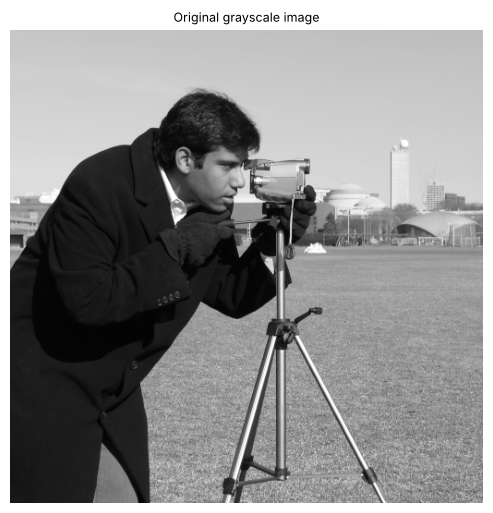

In [2]:
IMAGE_PATH = "image.png"        # replace with your own grayscale-able JPG/PNG (>= 300 x 300)
img = cv.imread(IMAGE_PATH, cv.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Please place {IMAGE_PATH} next to this notebook")
assert img.dtype == np.uint8 and img.ndim == 2 and min(img.shape) >= 300, "need 8-bit gray image >= 300x300"

original_backup = img.copy()    # used at the end to prove the original was never modified
img.flags.writeable = False     # any accidental in-place edit now raises an error

print("shape :", img.shape)
print("dtype :", img.dtype)
print("min   :", int(img.min()))
print("max   :", int(img.max()))
RESULTS["img"]["props"] = {"shape": list(img.shape), "dtype": str(img.dtype), "min": int(img.min()), "max": int(img.max())}

show([img], ["Original grayscale image"], "fig00_original", figw=5)

**Numeric-safety rules used throughout:** (1) integer arithmetic is done in `int16`/`int64` and fractional arithmetic in `float32`/`float64`;
(2) results are clipped to 0–255 *before* converting back to `uint8`; (3) `astype(np.uint8)` **truncates** fractions;
(4) every `imshow` uses `vmin=0, vmax=255` so that Matplotlib does not silently stretch the display range.

## 1. Brightness adjustment  (s = r + β)

### 1.1 Dry run — pixels [30, 80, 128, 180, 240], β = +40 and −40

In [3]:
px = np.array([30, 80, 128, 180, 240])
px_u8 = px.astype(np.uint8)

for beta in (+40, -40):
    raw = px + beta                                   # int64: cannot overflow
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    wrapped = (px_u8 + beta) if beta > 0 else (px_u8 - abs(beta))   # NAIVE uint8 arithmetic (wraps)
    status = ["overflow (>255)" if v > 255 else "underflow (<0)" if v < 0 else "ok" for v in raw]
    dry(f"1_{'plus' if beta > 0 else 'minus'}", f"Brightness beta = {beta:+d}",
        ["r", "raw r+beta", "status", "clipped", "final uint8", "naive uint8 (wraps)"],
        [(a, b, s, c, d, e) for a, b, s, c, d, e in zip(px, raw, status, clipped, final, wrapped)])
    check = np.clip(px_u8.astype(np.int16) + beta, 0, 255).astype(np.uint8)
    assert np.array_equal(final, check)
    print("Python verification (int16 + clip + uint8):", check.tolist(), "-> matches hand calculation\n")

print("Lost detail: for +40 every r >= 215 collapses to 255 (41 levels -> 1);")
print("             for -40 every r <= 40 collapses to 0 (41 levels -> 1).")

Brightness beta = +40
    r | raw r+beta |          status | clipped | final uint8 | naive uint8 (wraps)
  ----+------------+-----------------+---------+-------------+--------------------
   30 |         70 |              ok |      70 |          70 |                  70
   80 |        120 |              ok |     120 |         120 |                 120
  128 |        168 |              ok |     168 |         168 |                 168
  180 |        220 |              ok |     220 |         220 |                 220
  240 |        280 | overflow (>255) |     255 |         255 |                  24

Python verification (int16 + clip + uint8): [70, 120, 168, 220, 255] -> matches hand calculation

Brightness beta = -40
    r | raw r+beta |         status | clipped | final uint8 | naive uint8 (wraps)
  ----+------------+----------------+---------+-------------+--------------------
   30 |        -10 | underflow (<0) |       0 |           0 |                 246
   80 |         40 |          

### 1.2 Image: β = +40 and −40 (NumPy) and +40 with nested loops

Loop result identical to NumPy result: True
{'mean_orig': 129.06072616577148, 'mean_plus': 168.64921188354492, 'mean_minus': 93.68223571777344, 'pct_sat255': 3.9646148681640625, 'pct_orig255': 0.1033782958984375, 'pct_zero_minus': 26.67694091796875, 'pct_orig0': 0.0003814697265625, 'loop_equal': True}


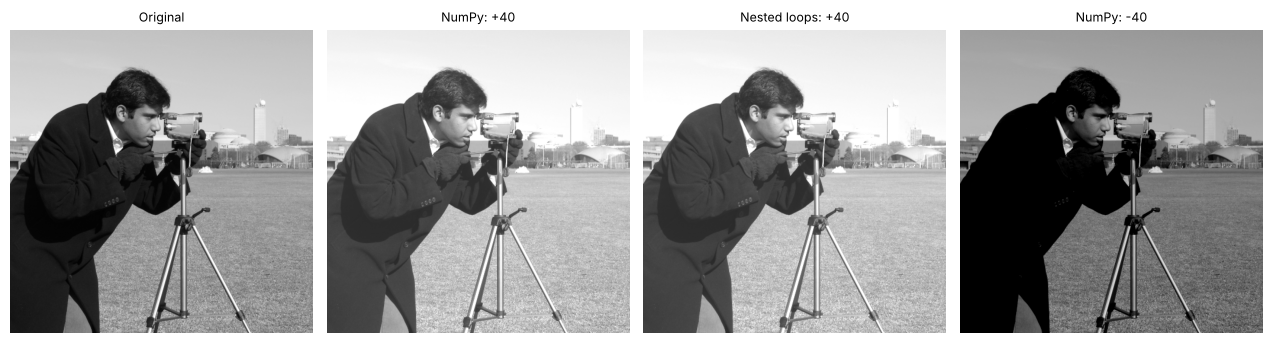

In [4]:
def brightness(a, beta):
    return np.clip(a.astype(np.int16) + beta, 0, 255).astype(np.uint8)

bright = brightness(img, +40)
darker = brightness(img, -40)

# nested-loop version of +40
height, width = img.shape
bright_loop = np.zeros_like(img)
for row in range(height):
    for col in range(width):
        pixel = int(img[row, col])                 # int(): avoid unsigned 8-bit arithmetic
        bright_loop[row, col] = min(255, max(0, pixel + 40))

same = np.array_equal(bright, bright_loop)
print("Loop result identical to NumPy result:", same)
assert same

RESULTS["img"]["bright"] = {
    "mean_orig": float(img.mean()), "mean_plus": float(bright.mean()), "mean_minus": float(darker.mean()),
    "pct_sat255": float((bright == 255).mean() * 100), "pct_orig255": float((img == 255).mean() * 100),
    "pct_zero_minus": float((darker == 0).mean() * 100), "pct_orig0": float((img == 0).mean() * 100),
    "loop_equal": bool(same)}
print(RESULTS["img"]["bright"])
show([img, bright, bright_loop, darker],
     ["Original", "NumPy: +40", "Nested loops: +40", "NumPy: -40"], "fig01_brightness")

## 2. Linear contrast from zero  (s = αr + β, α = 1.5, β = 0)

### 2.1 Dry run — pixels [30, 80, 128, 180, 240]

In [5]:
alpha, beta = 1.5, 0.0
raw = alpha * px.astype(np.float64) + beta
clipped = np.clip(raw, 0, 255)
final = clipped.astype(np.uint8)                      # truncation
dry("2", "Linear contrast alpha = 1.5, beta = 0",
    ["r", "1.5 r", "clipped 0-255", "truncated uint8", "saturated?"],
    [(a, f"{b:g}", f"{c:g}", d, "YES (>255)" if b > 255 else "no") for a, b, c, d in zip(px, raw, clipped, final)])
assert np.array_equal(final, np.clip(alpha * px_u8.astype(np.float32) + beta, 0, 255).astype(np.uint8))
print("Python verification matches:", final.tolist())
print("Saturated pixels (raw > 255):", px[raw > 255].tolist())

Linear contrast alpha = 1.5, beta = 0
    r | 1.5 r | clipped 0-255 | truncated uint8 | saturated?
  ----+-------+---------------+-----------------+-----------
   30 |    45 |            45 |              45 |         no
   80 |   120 |           120 |             120 |         no
  128 |   192 |           192 |             192 |         no
  180 |   270 |           255 |             255 | YES (>255)
  240 |   360 |           255 |             255 | YES (>255)

Python verification matches: [45, 120, 192, 255, 255]
Saturated pixels (raw > 255): [180, 240]


### 2.2 Image

{'mean_orig': 129.06072616577148, 'mean_lin': 176.30985641479492, 'std_orig': 73.64484655630552, 'std_lin': 93.9948330594015, 'pct_sat': 34.41619873046875, 'threshold_r': 170.0}


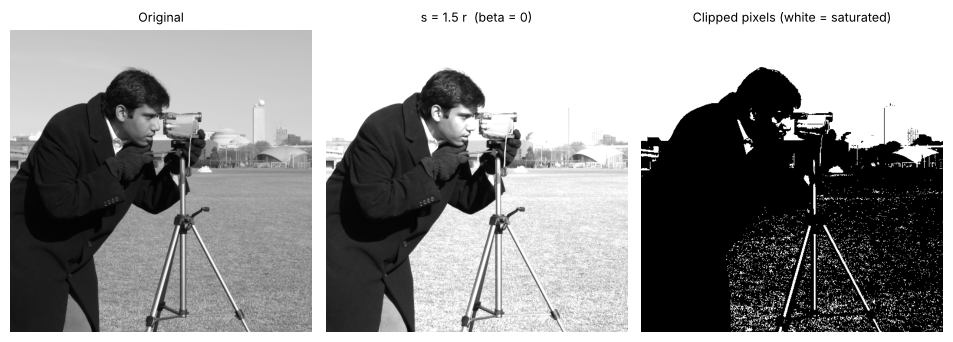

In [6]:
alpha, beta = 1.5, 0
lin_raw = alpha * img.astype(np.float32) + beta
linear = np.clip(lin_raw, 0, 255).astype(np.uint8)
sat_mask = (lin_raw > 255)

RESULTS["img"]["linear"] = {"mean_orig": float(img.mean()), "mean_lin": float(linear.mean()),
                            "std_orig": float(img.std()), "std_lin": float(linear.std()),
                            "pct_sat": float(sat_mask.mean() * 100), "threshold_r": 255 / alpha}
print(RESULTS["img"]["linear"])
show([img, linear, sat_mask.astype(np.uint8) * 255],
     ["Original", "s = 1.5 r  (beta = 0)", "Clipped pixels (white = saturated)"], "fig02_linear")

## 3. Contrast centered at 128  (s = (r − 128)·α + 128)

### 3.1 Dry run — pixels [30, 80, 128, 180, 240], α = 1.5 and 0.5

In [7]:
for a_ in (1.5, 0.5):
    d1 = px - 128
    d2 = d1 * a_
    d3 = d2 + 128
    cl = np.clip(d3, 0, 255)
    fin = cl.astype(np.uint8)
    dry(f"3_{a_}", f"Centered contrast alpha = {a_}",
        ["r", "r-128", f"x {a_}", "+128", "clipped", "final uint8"],
        [(r, i, f"{j:g}", f"{k:g}", f"{l:g}", m) for r, i, j, k, l, m in zip(px, d1, d2, d3, cl, fin)])
    assert np.array_equal(fin, np.clip((px_u8.astype(np.float32) - 128) * a_ + 128, 0, 255).astype(np.uint8))
    print("Python verification matches:", fin.tolist(), "\n")

zero15 = np.clip(1.5 * px.astype(float), 0, 255).astype(np.uint8)
c15 = np.clip((px - 128) * 1.5 + 128, 0, 255).astype(np.uint8)
c05 = np.clip((px - 128) * 0.5 + 128, 0, 255).astype(np.uint8)
dry("3_cmp", "Comparison of the three contrast rules",
    ["r", "from zero 1.5r", "centered 1.5", "centered 0.5"],
    [(r, a, b, c) for r, a, b, c in zip(px, zero15, c15, c05)])
print("r = 128 is the pivot: (128-128)*alpha + 128 = 128 for ANY alpha, so mid-gray never changes.")

Centered contrast alpha = 1.5
    r | r-128 | x 1.5 | +128 | clipped | final uint8
  ----+-------+-------+------+---------+------------
   30 |   -98 |  -147 |  -19 |       0 |           0
   80 |   -48 |   -72 |   56 |      56 |          56
  128 |     0 |     0 |  128 |     128 |         128
  180 |    52 |    78 |  206 |     206 |         206
  240 |   112 |   168 |  296 |     255 |         255

Python verification matches: [0, 56, 128, 206, 255] 

Centered contrast alpha = 0.5
    r | r-128 | x 0.5 | +128 | clipped | final uint8
  ----+-------+-------+------+---------+------------
   30 |   -98 |   -49 |   79 |      79 |          79
   80 |   -48 |   -24 |  104 |     104 |         104
  128 |     0 |     0 |  128 |     128 |         128
  180 |    52 |    26 |  154 |     154 |         154
  240 |   112 |    56 |  184 |     184 |         184

Python verification matches: [79, 104, 128, 154, 184] 

Comparison of the three contrast rules
    r | from zero 1.5r | centered 1.5 | centere

### 3.2 Image

orig {'mean': 129.06072616577148, 'std': 73.64484655630552, 'min': 0, 'max': 255, 'pct0': 0.0003814697265625, 'pct255': 0.1033782958984375}
zero15 {'mean': 176.30985641479492, 'std': 93.9948330594015, 'min': 0, 'max': 255, 'pct0': 0.0003814697265625, 'pct255': 34.83238220214844}
c15 {'mean': 136.65204238891602, 'std': 97.70168966369653, 'min': 0, 'max': 255, 'pct0': 27.201080322265625, 'pct255': 5.8502197265625}
c05 {'mean': 128.281982421875, 'std': 36.82289160071585, 'min': 64, 'max': 191, 'pct0': 0.0, 'pct255': 0.0}


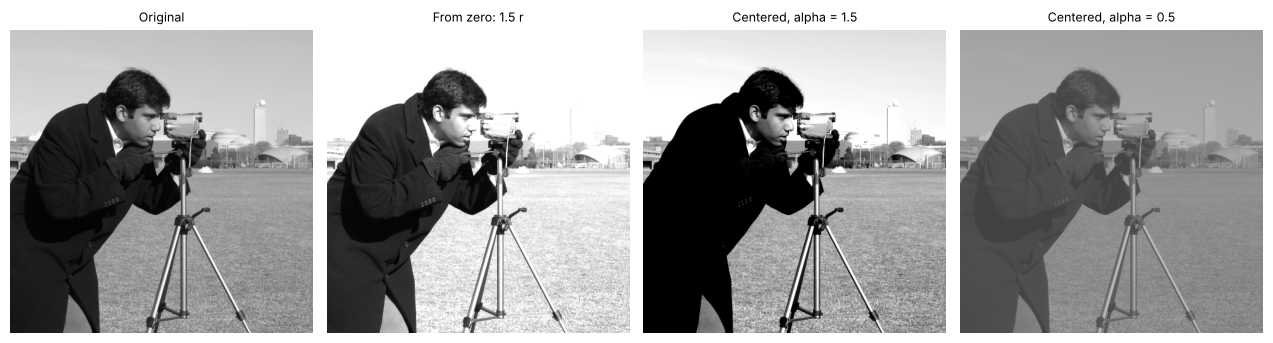

In [8]:
def centered_contrast(a, alpha):
    return np.clip((a.astype(np.float32) - 128) * alpha + 128, 0, 255).astype(np.uint8)

cen15 = centered_contrast(img, 1.5)
cen05 = centered_contrast(img, 0.5)

def stats(a):
    return {"mean": float(a.mean()), "std": float(a.std()), "min": int(a.min()), "max": int(a.max()),
            "pct0": float((a == 0).mean() * 100), "pct255": float((a == 255).mean() * 100)}
RESULTS["img"]["centered"] = {"orig": stats(img), "zero15": stats(linear), "c15": stats(cen15), "c05": stats(cen05)}
for k, v in RESULTS["img"]["centered"].items(): print(k, v)
show([img, linear, cen15, cen05],
     ["Original", "From zero: 1.5 r", "Centered, alpha = 1.5", "Centered, alpha = 0.5"], "fig03_centered")

## 4. Image negative  (s = 255 − r)

### 4.1 Dry run — pixels [30, 80, 128, 180, 240]

In [9]:
neg = 255 - px_u8
neg2 = 255 - neg
dry("4", "Image negative and double negative",
    ["r", "255 - r", "negative again", "equals original?"],
    [(r, n, n2, "yes" if r == n2 else "NO") for r, n, n2 in zip(px, neg, neg2)])
assert np.array_equal(neg2, px_u8)
print("Applying the negative twice restores the original exactly (it is its own inverse).")

Image negative and double negative
    r | 255 - r | negative again | equals original?
  ----+---------+----------------+-----------------
   30 |     225 |             30 |              yes
   80 |     175 |             80 |              yes
  128 |     127 |            128 |              yes
  180 |      75 |            180 |              yes
  240 |      15 |            240 |              yes

Applying the negative twice restores the original exactly (it is its own inverse).


### 4.2 Image

{'mean_orig': 129.06072616577148, 'mean_neg': 125.93927383422852, 'restored_equal': True}


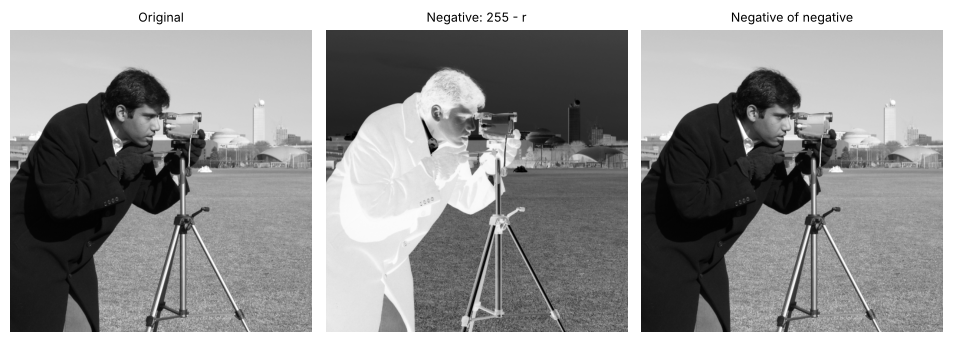

In [10]:
negative = 255 - img
restored = 255 - negative
assert np.array_equal(restored, img)
RESULTS["img"]["negative"] = {"mean_orig": float(img.mean()), "mean_neg": float(negative.mean()),
                              "restored_equal": True}
print(RESULTS["img"]["negative"])
show([img, negative, restored], ["Original", "Negative: 255 - r", "Negative of negative"], "fig04_negative")

**When is the negative useful?** When bright/gray detail is embedded in a large dark region — e.g. a small bright lesion on a dark X-ray or
mammogram background. After inversion the same detail appears as dark structure on a light background, which the eye often inspects more easily.

## 5. Gamma correction  (s = 255·(r/255)^γ)

### 5.1 Dry run — pixels [0, 64, 128, 192, 255], γ = 0.5 and 2.0 (full precision, truncate only at the end)

In [11]:
gpx = np.array([0, 64, 128, 192, 255])
for g in (0.5, 2.0):
    norm = gpx.astype(np.float64) / 255
    powr = np.power(norm, g)
    scaled = 255 * powr
    final = np.clip(scaled, 0, 255).astype(np.uint8)            # truncation
    rounded = np.rint(scaled).astype(int)                       # what the slide shows
    dry(f"5_{g}", f"Gamma = {g}",
        ["r", "r/255", f"(r/255)^{g}", "x 255 (full precision)", "final (truncated)", "rounded (slide style)"],
        [(r, f"{n:.6f}", f"{p:.6f}", f"{s:.4f}", f_, rd) for r, n, p, s, f_, rd in zip(gpx, norm, powr, scaled, final, rounded)])
    assert final[0] == 0 and final[-1] == 255
print("0 and 255 stay fixed: 0^g = 0 and 1^g = 1 for every gamma.")
print("Slide (gamma 0.5) rounds 127.75 -> 128 and 180.67 -> 181; truncation gives 127 and 180. 221.27 gives 221 either way.")

Gamma = 0.5
    r |    r/255 | (r/255)^0.5 | x 255 (full precision) | final (truncated) | rounded (slide style)
  ----+----------+-------------+------------------------+-------------------+----------------------
    0 | 0.000000 |    0.000000 |                 0.0000 |                 0 |                     0
   64 | 0.250980 |    0.500979 |               127.7498 |               127 |                   128
  128 | 0.501961 |    0.708492 |               180.6654 |               180 |                   181
  192 | 0.752941 |    0.867722 |               221.2691 |               221 |                   221
  255 | 1.000000 |    1.000000 |               255.0000 |               255 |                   255

Gamma = 2.0
    r |    r/255 | (r/255)^2.0 | x 255 (full precision) | final (truncated) | rounded (slide style)
  ----+----------+-------------+------------------------+-------------------+----------------------
    0 | 0.000000 |    0.000000 |                 0.0000 |                 0

### 5.2 Image

LUT check: output(0) = 0 and output(255) = 255 for gamma 0.5 and 2.0
Image check: pixels equal to 0 unchanged: True | pixels equal to 255 unchanged: True
{'pct_dark': 29.590606689453125, 'dark_mean_orig': 25.390937217996647, 'dark_mean_g05': 76.9385329379915, 'dark_mean_g20': 2.7143998968673455, 'mean_orig': 129.06072616577148, 'mean_g05': 169.2802734375, 'mean_g20': 86.14073181152344}


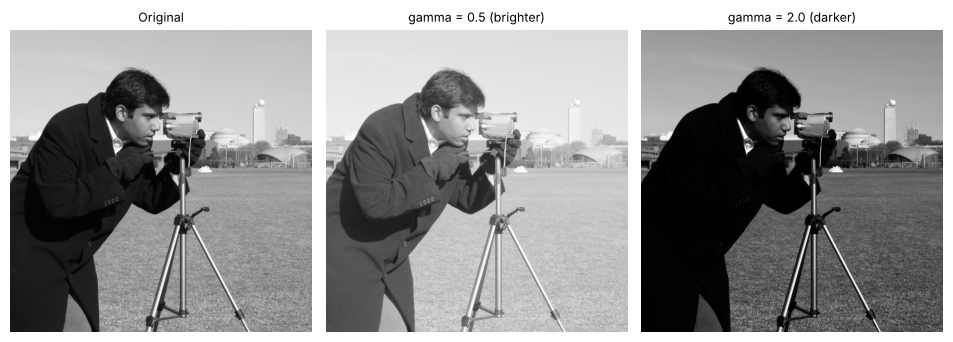

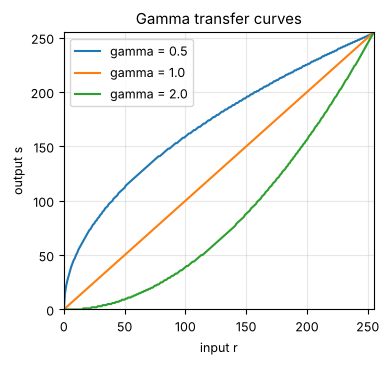

In [12]:
def gamma_lut(g):
    r = np.arange(256, dtype=np.float64) / 255
    return np.clip(255 * np.power(r, g), 0, 255).astype(np.uint8)

def gamma_correct(a, g):
    return np.clip(255 * np.power(a.astype(np.float32) / 255.0, g), 0, 255).astype(np.uint8)

g05 = gamma_correct(img, 0.5)
g20 = gamma_correct(img, 2.0)

for g in (0.5, 2.0):
    L = gamma_lut(g)
    assert L[0] == 0 and L[255] == 255
print("LUT check: output(0) = 0 and output(255) = 255 for gamma 0.5 and 2.0")
print("Image check: pixels equal to 0 unchanged:", bool(np.all(g05[img == 0] == 0) and np.all(g20[img == 0] == 0)),
      "| pixels equal to 255 unchanged:", bool(np.all(g05[img == 255] == 255) and np.all(g20[img == 255] == 255)))

dark = img < 64
RESULTS["img"]["gamma"] = {"pct_dark": float(dark.mean() * 100),
    "dark_mean_orig": float(img[dark].mean()), "dark_mean_g05": float(g05[dark].mean()), "dark_mean_g20": float(g20[dark].mean()),
    "mean_orig": float(img.mean()), "mean_g05": float(g05.mean()), "mean_g20": float(g20.mean())}
print(RESULTS["img"]["gamma"])
show([img, g05, g20], ["Original", "gamma = 0.5 (brighter)", "gamma = 2.0 (darker)"], "fig05_gamma")

x = np.arange(256)
plt.figure(figsize=(4, 3.6))
for g in (0.5, 1.0, 2.0): plt.plot(x, gamma_lut(g), label=f"gamma = {g}")
plt.xlabel("input r"); plt.ylabel("output s"); plt.title("Gamma transfer curves"); plt.legend(); plt.grid(alpha=.3)
plt.xlim(0, 255); plt.ylim(0, 255); save("fig05b_gamma_curves"); plt.show()

## 6. Grayscale histogram

### 6.1 Dry run — A = [[0, 50, 50, 100], [100, 150, 200, 255]]

In [13]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
vals, cnts = np.unique(A, return_counts=True)
total = A.size
dry("6", f"Histogram of A (total pixels = {total})",
    ["intensity", "frequency", "probability (fraction)", "probability (decimal)"],
    [(v, c, Fraction(int(c), total), f"{c / total:.3f}") for v, c in zip(vals, cnts)])
print("Sum of frequencies:", int(cnts.sum()), "| sum of probabilities:", float((cnts / total).sum()))

B = A.ravel()[[7, 2, 5, 0, 3, 6, 1, 4]].reshape(2, 4)       # same pixels, different positions
same_hist = np.array_equal(np.bincount(A.ravel(), minlength=256), np.bincount(B.ravel(), minlength=256))
print("A =", A.tolist()); print("B =", B.tolist())
print("A and B are different images:", not np.array_equal(A, B), "| identical histograms:", same_hist)
print("-> a histogram stores only COUNTS per intensity, never WHERE the pixels are.")
assert same_hist

Histogram of A (total pixels = 8)
  intensity | frequency | probability (fraction) | probability (decimal)
  ----------+-----------+------------------------+----------------------
          0 |         1 |                    1/8 |                 0.125
         50 |         2 |                    1/4 |                 0.250
        100 |         2 |                    1/4 |                 0.250
        150 |         1 |                    1/8 |                 0.125
        200 |         1 |                    1/8 |                 0.125
        255 |         1 |                    1/8 |                 0.125

Sum of frequencies: 8 | sum of probabilities: 1.0
A = [[0, 50, 50, 100], [100, 150, 200, 255]]
B = [[255, 50, 150, 0], [100, 200, 50, 100]]
A and B are different images: True | identical histograms: True
-> a histogram stores only COUNTS per intensity, never WHERE the pixels are.


### 6.2 Image

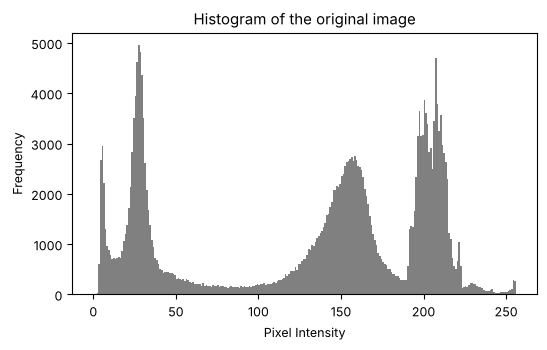

{'mean': 129.06072616577148, 'median': 152.0, 'std': 73.64484655630552, 'pct_dark': 30.939102172851562, 'pct_mid': 34.228515625, 'pct_bright': 34.83238220214844, 'peak': 27, 'p5': 12.0, 'p95': 213.0}


In [14]:
plt.figure(figsize=(6, 3.4))
plt.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
plt.xlabel("Pixel Intensity"); plt.ylabel("Frequency"); plt.title("Histogram of the original image")
save("fig06_hist"); plt.show()

h = np.bincount(img.ravel(), minlength=256)
RESULTS["img"]["hist"] = {"mean": float(img.mean()), "median": float(np.median(img)), "std": float(img.std()),
    "pct_dark": float((img < 85).mean() * 100), "pct_mid": float(((img >= 85) & (img < 170)).mean() * 100),
    "pct_bright": float((img >= 170).mean() * 100), "peak": int(h.argmax()), "p5": float(np.percentile(img, 5)), "p95": float(np.percentile(img, 95))}
print(RESULTS["img"]["hist"])

## 7. Global histogram equalization

### 7.1 Dry run — pixels [50, 50, 100, 150]

In [15]:
ep = np.array([50, 50, 100, 150], dtype=np.uint8)
v, c = np.unique(ep, return_counts=True)
cum = np.cumsum(c); n = int(ep.size)
cdf = [Fraction(int(k), n) for k in cum]
cdf_min = min(x for x in cdf if x > 0)
map1 = [rhu(255 * x) for x in cdf]
map2 = [rhu(255 * (x - cdf_min) / (1 - cdf_min)) for x in cdf]
dry("7", "Equalization mapping (round to nearest, .5 up)",
    ["value", "freq", "cumulative", "CDF", "255*CDF", "map 1", "255*(CDF-CDFmin)/(1-CDFmin)", "map 2"],
    [(a, b, d, e, f"{float(255 * e):.2f}", m1, f"{float(255 * (e - cdf_min) / (1 - cdf_min)):.2f}", m2)
     for a, b, d, e, m1, m2 in zip(v, c, cum, cdf, map1, map2)])
lut1, lut2 = dict(zip(v.tolist(), map1)), dict(zip(v.tolist(), map2))
out1 = [lut1[int(p)] for p in ep]; out2 = [lut2[int(p)] for p in ep]
cv_out = cv.equalizeHist(ep.reshape(1, -1)).ravel().tolist()
print("Output list, formula 1 (255*CDF)               :", out1)
print("Output list, formula 2 (CDF-CDFmin normalised) :", out2)
print("cv2.equalizeHist output                        :", cv_out)
assert out2 == cv_out
print("Formula 2 matches OpenCV exactly.")

Equalization mapping (round to nearest, .5 up)
  value | freq | cumulative | CDF | 255*CDF | map 1 | 255*(CDF-CDFmin)/(1-CDFmin) | map 2
  ------+------+------------+-----+---------+-------+-----------------------------+------
     50 |    2 |          2 | 1/2 |  127.50 |   128 |                        0.00 |     0
    100 |    1 |          3 | 3/4 |  191.25 |   191 |                      127.50 |   128
    150 |    1 |          4 |   1 |  255.00 |   255 |                      255.00 |   255

Output list, formula 1 (255*CDF)               : [128, 128, 191, 255]
Output list, formula 2 (CDF-CDFmin normalised) : [0, 0, 128, 255]
cv2.equalizeHist output                        : [0, 0, 128, 255]
Formula 2 matches OpenCV exactly.


### 7.2 Image

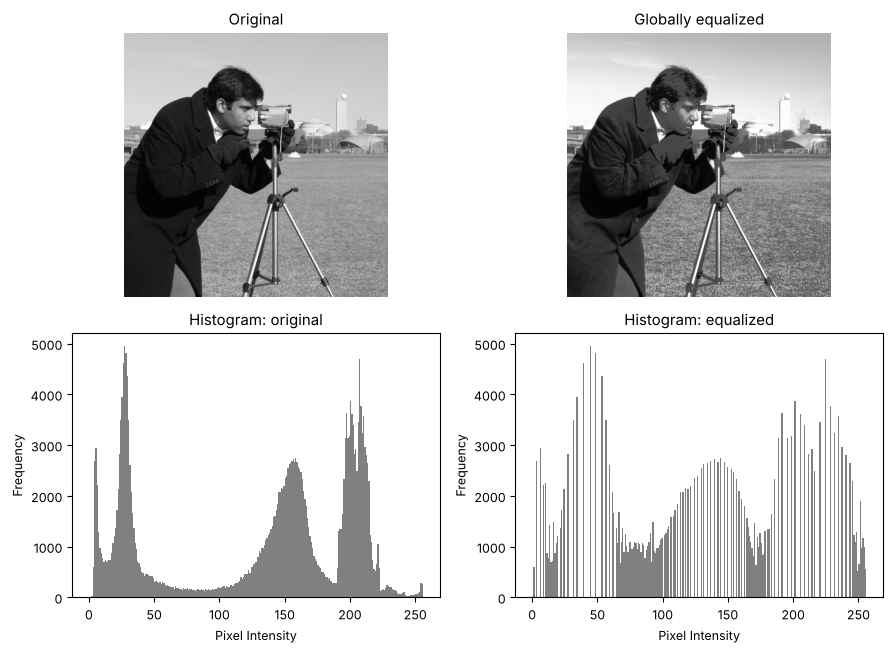

In [16]:
equalized = cv.equalizeHist(img)

fig, axes = plt.subplots(2, 2, figsize=(9, 6.6))
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255);       axes[0, 0].set_title("Original"); axes[0, 0].axis("off")
axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255); axes[0, 1].set_title("Globally equalized"); axes[0, 1].axis("off")
axes[1, 0].hist(img.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 0].set(title="Histogram: original", xlabel="Pixel Intensity", ylabel="Frequency")
axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 1].set(title="Histogram: equalized", xlabel="Pixel Intensity", ylabel="Frequency")
plt.tight_layout(); save("fig07_equalize"); plt.show()

## 8. CLAHE  (clipLimit = 2.0, tileGridSize = (8, 8))

### 8.1 Dry run — histogram [6, 2, 0, 0], absolute bin cap = 4

In [17]:
hist = [Fraction(x) for x in (6, 2, 0, 0)]
cap = Fraction(4)
clipped = [min(x, cap) for x in hist]
excess = sum(hist) - sum(clipped)
add = excess / len(hist)
new = [x + add for x in clipped]
cum_new = [sum(new[:i + 1]) for i in range(4)]
cdf_new = [x / sum(new) for x in cum_new]
cum_old = [sum(hist[:i + 1]) for i in range(4)]
cdf_old = [x / sum(hist) for x in cum_old]
dry("8", f"Simplified clipped histogram (excess = {excess}, redistributed {add} per bin)",
    ["bin", "original", "clipped at 4", "+ excess/4", "new count", "cumulative", "new CDF", "old CDF (no clip)"],
    [(i, hist[i], clipped[i], add, new[i], cum_new[i], f"{cdf_new[i]} = {float(cdf_new[i]):.4f}", f"{cdf_old[i]} = {float(cdf_old[i]):.4f}")
     for i in range(4)])
assert sum(new) == sum(hist)
print("Total count preserved:", sum(new))
print("New mapping to levels 0-3 (3*CDF):", [f"{float(3 * x):.4f}" for x in cdf_new], " vs unclipped:", [f"{float(3 * x):.2f}" for x in cdf_old])
print("Note: the simplified model leaves bin 0 at 4.5 (> cap 4); OpenCV redistributes with integers and handles the residue itself.")

Simplified clipped histogram (excess = 2, redistributed 1/2 per bin)
  bin | original | clipped at 4 | + excess/4 | new count | cumulative |        new CDF | old CDF (no clip)
  ----+----------+--------------+------------+-----------+------------+----------------+------------------
    0 |        6 |            4 |        1/2 |       9/2 |        9/2 |  9/16 = 0.5625 |      3/4 = 0.7500
    1 |        2 |            2 |        1/2 |       5/2 |          7 |   7/8 = 0.8750 |        1 = 1.0000
    2 |        0 |            0 |        1/2 |       1/2 |       15/2 | 15/16 = 0.9375 |        1 = 1.0000
    3 |        0 |            0 |        1/2 |       1/2 |          8 |     1 = 1.0000 |        1 = 1.0000

Total count preserved: 8
New mapping to levels 0-3 (3*CDF): ['1.6875', '2.6250', '2.8125', '3.0000']  vs unclipped: ['2.25', '3.00', '3.00', '3.00']
Note: the simplified model leaves bin 0 at 4.5 (> cap 4); OpenCV redistributes with integers and handles the residue itself.


### 8.2 Image

tileGridSize=(8, 8) means 8 x 8 = 64 TILES, so each tile is about 64 x 64 pixels (not 8 x 8 pixels).


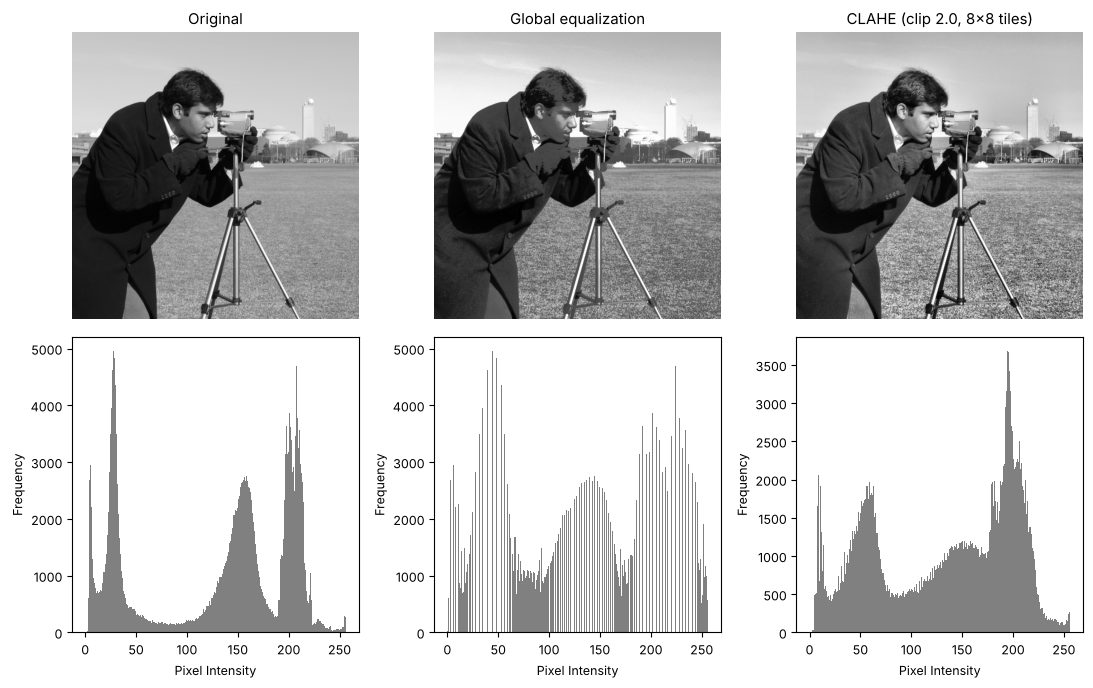

In [18]:
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced = clahe.apply(img)

H, W = img.shape
print(f"tileGridSize=(8, 8) means 8 x 8 = 64 TILES, so each tile is about {H // 8} x {W // 8} pixels (not 8 x 8 pixels).")

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for j, (im, t) in enumerate(zip([img, equalized, enhanced], ["Original", "Global equalization", "CLAHE (clip 2.0, 8x8 tiles)"])):
    axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(t); axes[0, j].axis("off")
    axes[1, j].hist(im.ravel(), bins=256, range=(0, 256), color="gray")
    axes[1, j].set(xlabel="Pixel Intensity", ylabel="Frequency")
plt.tight_layout(); save("fig08_clahe"); plt.show()

### 7.3 / 8.3 Quantifying detail and noise (supports the discussion of operations 7 and 8)

image      global std  local std  entropy  flat std  dark std
original        73.64      14.90    7.232      2.83     36.08
equalized       73.67      19.22    6.945      6.87     34.21
clahe           67.64      22.91    7.687      6.27     40.62


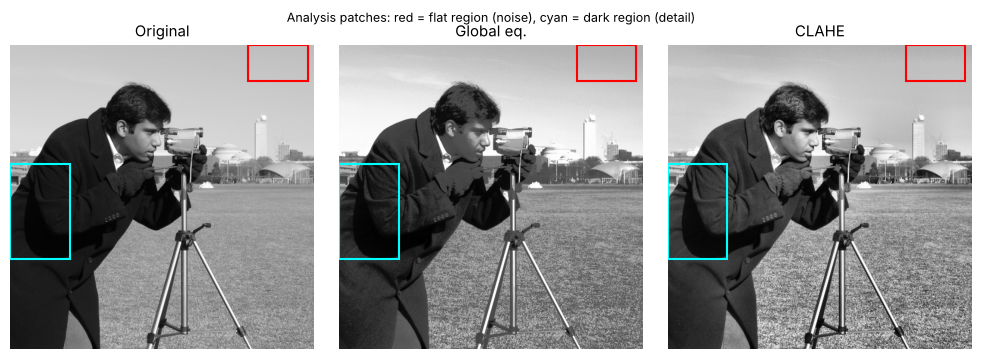

In [19]:
def local_std(a, k=15):
    f = a.astype(np.float32)
    m = cv.blur(f, (k, k)); m2 = cv.blur(f * f, (k, k))
    return float(np.sqrt(np.maximum(m2 - m * m, 0)).mean())

def entropy(a):
    p = np.bincount(a.ravel(), minlength=256) / a.size
    p = p[p > 0]; return float(-(p * np.log2(p)).sum())

# a visually flat patch (sky / wall) to estimate noise, and a dark patch to judge shadow detail
flat_rc = (slice(0, 60), slice(400, 500))
dark_rc = (slice(200, 360), slice(0, 100))   # clothing / dark foreground area

def patch_std(a, rc): return float(a[rc].std())
rows = {}
for name, im in [("original", img), ("equalized", equalized), ("clahe", enhanced)]:
    rows[name] = {"global_std": float(im.std()), "local_std": local_std(im), "entropy": entropy(im),
                  "flat_patch_std": patch_std(im, flat_rc), "dark_patch_std": patch_std(im, dark_rc),
                  "flat_patch_mean": float(im[flat_rc].mean()), "dark_patch_mean": float(im[dark_rc].mean())}
RESULTS["img"]["enh"] = rows
print(f"{'image':10s} {'global std':>10s} {'local std':>10s} {'entropy':>8s} {'flat std':>9s} {'dark std':>9s}")
for k, r in rows.items():
    print(f"{k:10s} {r['global_std']:10.2f} {r['local_std']:10.2f} {r['entropy']:8.3f} {r['flat_patch_std']:9.2f} {r['dark_patch_std']:9.2f}")

fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
for a_, im, t in zip(ax, [img, equalized, enhanced], ["Original", "Global eq.", "CLAHE"]):
    a_.imshow(im, cmap="gray", vmin=0, vmax=255); a_.set_title(t); a_.axis("off")
    for rc, col in ((flat_rc, "red"), (dark_rc, "cyan")):
        a_.add_patch(plt.Rectangle((rc[1].start, rc[0].start), rc[1].stop - rc[1].start, rc[0].stop - rc[0].start, fill=False, ec=col, lw=1.5))
plt.suptitle("Analysis patches: red = flat region (noise), cyan = dark region (detail)", fontsize=9)
plt.tight_layout(); save("fig08b_patches"); plt.show()

## 9. Fixed binary thresholding (T = 127)

### 9.1 Dry run — pixels [0, 80, 127, 128, 180, 255], rule: output 255 if r > T else 0

In [20]:
tp = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
res = {}
for T in (127, 180):
    out = np.where(tp > T, 255, 0).astype(np.uint8)
    res[T] = out
    ocv = cv.threshold(tp.reshape(1, -1), T, 255, cv.THRESH_BINARY)[1].ravel()
    assert np.array_equal(out, ocv)
dry("9", "Fixed thresholds T = 127 and T = 180",
    ["r", "r > 127 ?", "output T=127", "r > 180 ?", "output T=180"],
    [(r, "Yes" if r > 127 else "No", a, "Yes" if r > 180 else "No", b) for r, a, b in zip(tp, res[127], res[180])])
print("White pixels  T=127:", int((res[127] == 255).sum()), "   T=180:", int((res[180] == 255).sum()))
print("OpenCV verification matches for both thresholds. A pixel EQUAL to T is never white (strict >).")

Fixed thresholds T = 127 and T = 180
    r | r > 127 ? | output T=127 | r > 180 ? | output T=180
  ----+-----------+--------------+-----------+-------------
    0 |        No |            0 |        No |            0
   80 |        No |            0 |        No |            0
  127 |        No |            0 |        No |            0
  128 |       Yes |          255 |        No |            0
  180 |       Yes |          255 |        No |            0
  255 |       Yes |          255 |       Yes |          255

White pixels  T=127: 3    T=180: 1
OpenCV verification matches for both thresholds. A pixel EQUAL to T is never white (strict >).


### 9.2 Image

threshold returned: 127.0 | unique values: [0, 255] | white pixels: 64.30 %


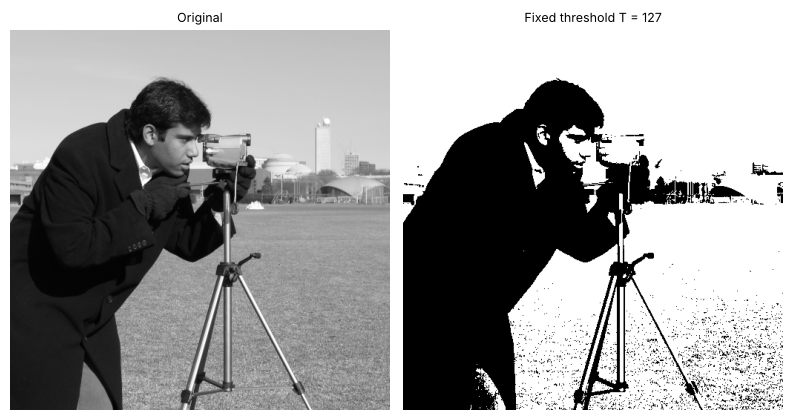

In [21]:
t_used, binary = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
uniq = np.unique(binary).tolist()
print("threshold returned:", t_used, "| unique values:", uniq, "| white pixels: %.2f %%" % ((binary == 255).mean() * 100))
RESULTS["img"]["fixed"] = {"t": float(t_used), "unique": uniq, "pct_white": float((binary == 255).mean() * 100)}
show([img, binary], ["Original", "Fixed threshold T = 127"], "fig09_fixed", figw=4)

## 10. Otsu thresholding

### 10.1 Dry run — pixels [0, 1, 4, 5] (no rescaling), classes: r ≤ T and r > T

In [22]:
op = np.array([0, 1, 4, 5])
rows, scores = [], {}
for T in range(0, 5):
    c0, c1 = op[op <= T], op[op > T]
    w0, w1 = Fraction(len(c0), len(op)), Fraction(len(c1), len(op))
    m0 = Fraction(int(c0.sum()), len(c0)); m1 = Fraction(int(c1.sum()), len(c1))
    s = w0 * w1 * (m0 - m1) ** 2
    scores[T] = s
    rows.append((T, c0.tolist(), c1.tolist(), w0, w1, m0, m1, f"{s} = {float(s):.4f}"))
dry("10", "Otsu between-class variance  w0*w1*(mu0-mu1)^2",
    ["T", "class 0 (r<=T)", "class 1 (r>T)", "w0", "w1", "mu0", "mu1", "w0 w1 (mu0-mu1)^2"], rows)
best = max(scores.values()); T_best = min(T for T, s in scores.items() if s == best)
pred = np.where(op > T_best, 255, 0).astype(np.uint8)
ret, ocv = cv.threshold(op.astype(np.uint8).reshape(1, -1), 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Maximum score:", float(best), "reached at T =", [T for T, s in scores.items() if s == best], "-> smallest tie chosen: T =", T_best)
print("Predicted mask:", pred.tolist())
print("OpenCV  : threshold =", ret, " mask =", ocv.ravel().tolist())
assert ret == T_best and np.array_equal(pred, ocv.ravel())
print("Prediction verified with OpenCV.")

Otsu between-class variance  w0*w1*(mu0-mu1)^2
  T | class 0 (r<=T) | class 1 (r>T) |  w0 |  w1 | mu0 |  mu1 | w0 w1 (mu0-mu1)^2
  --+----------------+---------------+-----+-----+-----+------+------------------
  0 |            [0] |     [1, 4, 5] | 1/4 | 3/4 |   0 | 10/3 |    25/12 = 2.0833
  1 |         [0, 1] |        [4, 5] | 1/2 | 1/2 | 1/2 |  9/2 |        4 = 4.0000
  2 |         [0, 1] |        [4, 5] | 1/2 | 1/2 | 1/2 |  9/2 |        4 = 4.0000
  3 |         [0, 1] |        [4, 5] | 1/2 | 1/2 | 1/2 |  9/2 |        4 = 4.0000
  4 |      [0, 1, 4] |           [5] | 3/4 | 1/4 | 5/3 |    5 |    25/12 = 2.0833

Maximum score: 4.0 reached at T = [1, 2, 3] -> smallest tie chosen: T = 1
Predicted mask: [0, 0, 255, 255]
OpenCV  : threshold = 1.0  mask = [0, 0, 255, 255]
Prediction verified with OpenCV.


### 10.2 Image

Otsu threshold returned by OpenCV: 102.0
{'t': 102.0, 'pct_white': 67.8955078125, 'pct_white_fixed': 64.30015563964844, 'pct_differ': 3.5953521728515625}


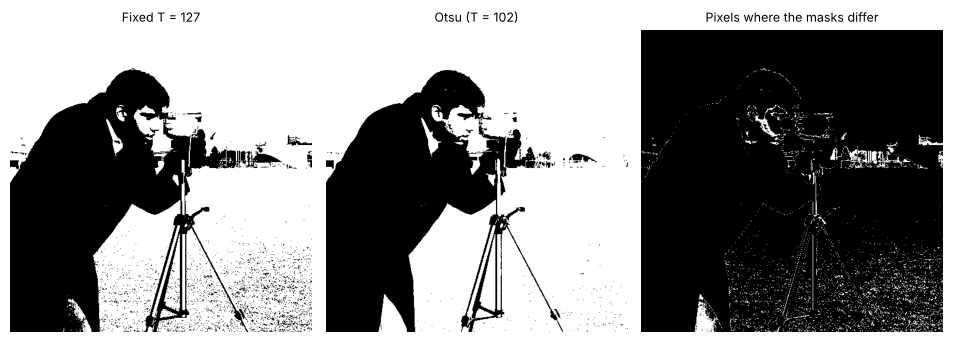

In [23]:
otsu_t, otsu = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
diff = (binary != otsu)
RESULTS["img"]["otsu"] = {"t": float(otsu_t), "pct_white": float((otsu == 255).mean() * 100),
                          "pct_white_fixed": float((binary == 255).mean() * 100), "pct_differ": float(diff.mean() * 100)}
print("Otsu threshold returned by OpenCV:", otsu_t)
print(RESULTS["img"]["otsu"])
show([binary, otsu, diff.astype(np.uint8) * 255],
     ["Fixed T = 127", f"Otsu (T = {otsu_t:.0f})", "Pixels where the masks differ"], "fig10_otsu")

## 11. Adaptive Gaussian thresholding (blockSize = 11, C = 2)

### 11.1 Dry run — 3×3 neighbourhood with Gaussian weights [[1,2,1],[2,4,2],[1,2,1]]/16

In [24]:
N = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]])
Wg = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
prod = N * Wg
wsum = int(prod.sum()); mean_w = Fraction(wsum, 16); Tloc = mean_w - 2
dry("11a", "Element-wise products  N x weights  (before dividing by 16)",
    ["", "col 0", "col 1", "col 2", "row sum"],
    [(f"row {i}", *prod[i].tolist(), int(prod[i].sum())) for i in range(3)])
print(f"Sum of products = {wsum}  ->  weighted mean = {wsum}/16 = {float(mean_w):g}   ->  T = mean - C = {float(mean_w):g} - 2 = {float(Tloc):g}")
center = int(N[1, 1])
dry("11b", "Classification with r > T",
    ["pixel", "value", "T", "r > T ?", "output"],
    [("center of the neighbourhood", center, float(Tloc), "Yes" if center > Tloc else "No", 255 if center > Tloc else 0),
     ("a pixel equal to T", float(Tloc), float(Tloc), "No (not strictly greater)", 0)])
ocv_ad = cv.adaptiveThreshold(N.astype(np.uint8), 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 3, 2)
print("OpenCV (blockSize=3 uses the same [1,2,1]/4 Gaussian) centre output:", int(ocv_ad[1, 1]))
assert int(ocv_ad[1, 1]) == 255

Element-wise products  N x weights  (before dividing by 16)
        | col 0 | col 1 | col 2 | row sum
  ------+-------+-------+-------+--------
  row 0 |   100 |   200 |   100 |     400
  row 1 |   200 |   480 |   280 |     960
  row 2 |   140 |   280 |   140 |     560

Sum of products = 1920  ->  weighted mean = 1920/16 = 120   ->  T = mean - C = 120 - 2 = 118
Classification with r > T
                        pixel | value |     T |                   r > T ? | output
  ----------------------------+-------+-------+---------------------------+-------
  center of the neighbourhood |   120 | 118.0 |                       Yes |    255
           a pixel equal to T | 118.0 | 118.0 | No (not strictly greater) |      0

OpenCV (blockSize=3 uses the same [1,2,1]/4 Gaussian) centre output: 255


### 11.2 Image (blockSize = 11, C = 2, Gaussian weighting)

{'pct_white': 73.1536865234375, 'agree_fixed': 63.84544372558594, 'agree_otsu': 62.33062744140625, 'agree_fixed_otsu': 96.40464782714844, 'flat_patch_white': 99.5, 'flat_patch_white_fixed': 100.0, 'flat_patch_white_otsu': 100.0}


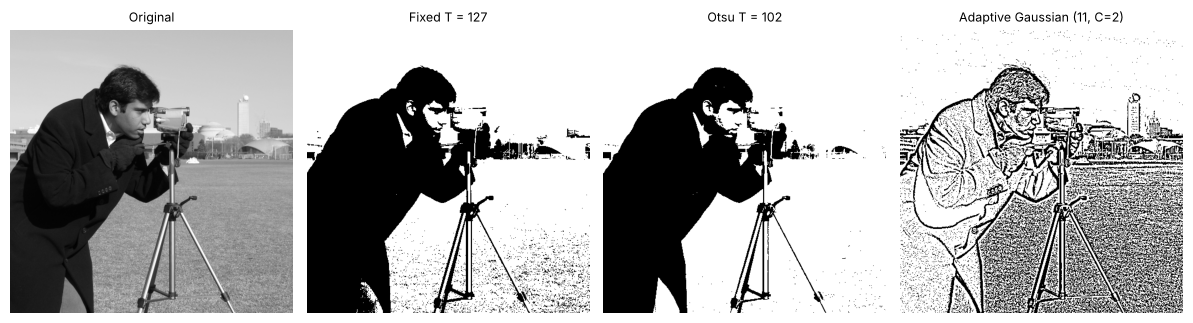

In [25]:
adaptive = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
def agree(a, b): return float((a == b).mean() * 100)
RESULTS["img"]["adaptive"] = {"pct_white": float((adaptive == 255).mean() * 100),
    "agree_fixed": agree(adaptive, binary), "agree_otsu": agree(adaptive, otsu), "agree_fixed_otsu": agree(binary, otsu),
    "flat_patch_white": float((adaptive[flat_rc] == 255).mean() * 100),
    "flat_patch_white_fixed": float((binary[flat_rc] == 255).mean() * 100),
    "flat_patch_white_otsu": float((otsu[flat_rc] == 255).mean() * 100)}
print(RESULTS["img"]["adaptive"])
show([img, binary, otsu, adaptive], ["Original", "Fixed T = 127", f"Otsu T = {otsu_t:.0f}", "Adaptive Gaussian (11, C=2)"], "fig11_adaptive", figw=3)

## 12. Final integrity check and export of results

In [26]:
assert np.array_equal(img, original_backup), "the original image was modified!"
print("Original image unchanged after all operations:", True)
RESULTS["img"]["unchanged"] = True
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=1)
print("results.json and figures/ written for the Word report")

Original image unchanged after all operations: True
results.json and figures/ written for the Word report
